<a href="https://colab.research.google.com/github/tantheta-art/ML_CNP/blob/main/BER_DNN%EC%8B%A4%EC%8A%B5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
#Colab사용시 아래 코드를 이용해서 파일 upload
import os
from pathlib import Path
from google.colab import files
# 기존 파일이 없다면 업로드 창을 띄웁니다.
CSV_PATH = Path('AdaptiveModulation_Random.csv')
if not CSV_PATH.exists():
    print("AdaptiveModulation_Random.csv 파일을 업로드해 주세요.")
    uploaded = files.upload()
else:
    print(f"{CSV_PATH.name} 파일이 이미 세션에 존재합니다.")

AdaptiveModulation_Random.csv 파일이 이미 세션에 존재합니다.


In [10]:
# -*- coding: utf-8 -*-
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from tensorflow import keras
from math import erfc

# 난수 생성 시드 설정
keras.utils.set_random_seed(42)

# 1. 파일 확인 및 데이터 불러오기
CSV = Path('AdaptiveModulation_Random.csv')
if not CSV.exists():
    raise FileNotFoundError("AdaptiveModulation_Random.csv 파일이 없습니다. 위 셀에서 업로드를 먼저 진행해 주세요.")

df = pd.read_csv(CSV, keep_default_na=False)
expected = ['SNR_dB', 'TargetBER', 'Modulation']
if list(df.columns) != expected:
    raise ValueError(f'CSV 열 구조 불일치. expected: {expected}')

labels = ['NA', 'BPSK', 'QPSK', 'QAM16']

In [11]:
# 2. 특징량(X) 및 정답 라벨(y) 구축
X = np.column_stack([
    df['SNR_dB'].to_numpy(dtype=float),
    np.log10(df['TargetBER'].to_numpy(dtype=float))
])
y = pd.Categorical(df['Modulation'], categories=labels).codes

# 3. 데이터셋 분할 (70 / 15 / 15)
X_tv, X_test, y_tv, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=0.15/0.85, random_state=42, stratify=y_tv)

# 4. 입력 특성 표준화
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 5. DNN 구조 정의
model = keras.Sequential([
    keras.layers.Input(shape=(2,)),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(8, activation='relu'),
    keras.layers.Dense(4, activation='softmax'),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [12]:
# 6. DNN 학습 진행 (에포크 출력 최소화)
print("DNN 학습을 시작합니다... (에포크 로그 출력 최소화)")

# 사용자 정의 간소화 콜백 생성
class SimpleProgressCallback(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:03d}/150 - loss: {logs['loss']:.4f} - val_loss: {logs['val_loss']:.4f} - accuracy: {logs['accuracy']:.4f} - val_accuracy: {logs['val_accuracy']:.4f}")

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=128,
    verbose=0, # 매 epoch 상세 텍스트 출력을 끕니다.
    callbacks=[
        SimpleProgressCallback(),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    ]
)
print("학습 완료!")

DNN 학습을 시작합니다... (에포크 로그 출력 최소화)
Epoch 001/150 - loss: 1.0231 - val_loss: 0.7516 - accuracy: 0.5468 - val_accuracy: 0.7013
Epoch 010/150 - loss: 0.0866 - val_loss: 0.0805 - accuracy: 0.9827 - val_accuracy: 0.9804
Epoch 020/150 - loss: 0.0520 - val_loss: 0.0498 - accuracy: 0.9883 - val_accuracy: 0.9891
Epoch 030/150 - loss: 0.0396 - val_loss: 0.0384 - accuracy: 0.9910 - val_accuracy: 0.9927
Epoch 040/150 - loss: 0.0330 - val_loss: 0.0323 - accuracy: 0.9919 - val_accuracy: 0.9931
Epoch 050/150 - loss: 0.0289 - val_loss: 0.0284 - accuracy: 0.9924 - val_accuracy: 0.9929
Epoch 060/150 - loss: 0.0261 - val_loss: 0.0257 - accuracy: 0.9928 - val_accuracy: 0.9927
Epoch 070/150 - loss: 0.0239 - val_loss: 0.0237 - accuracy: 0.9931 - val_accuracy: 0.9929
Epoch 080/150 - loss: 0.0223 - val_loss: 0.0221 - accuracy: 0.9936 - val_accuracy: 0.9931
Epoch 090/150 - loss: 0.0209 - val_loss: 0.0209 - accuracy: 0.9938 - val_accuracy: 0.9933
Epoch 100/150 - loss: 0.0199 - val_loss: 0.0200 - accuracy: 0.9940 


[시험 데이터 분류 결과]
              precision    recall  f1-score   support

          NA       1.00      1.00      1.00      1162
        BPSK       0.99      1.00      0.99       685
        QPSK       1.00      0.99      1.00      1479
       QAM16       1.00      1.00      1.00      1174

    accuracy                           1.00      4500
   macro avg       1.00      1.00      1.00      4500
weighted avg       1.00      1.00      1.00      4500

Target BER 위반율 (전체 시험 샘플 기준): 0.22%
전송 기회 누락률 (전체 시험 샘플 기준): 0.02%

학습된 모델이 'adaptive_modulation_dnn.keras'로 저장되었습니다.


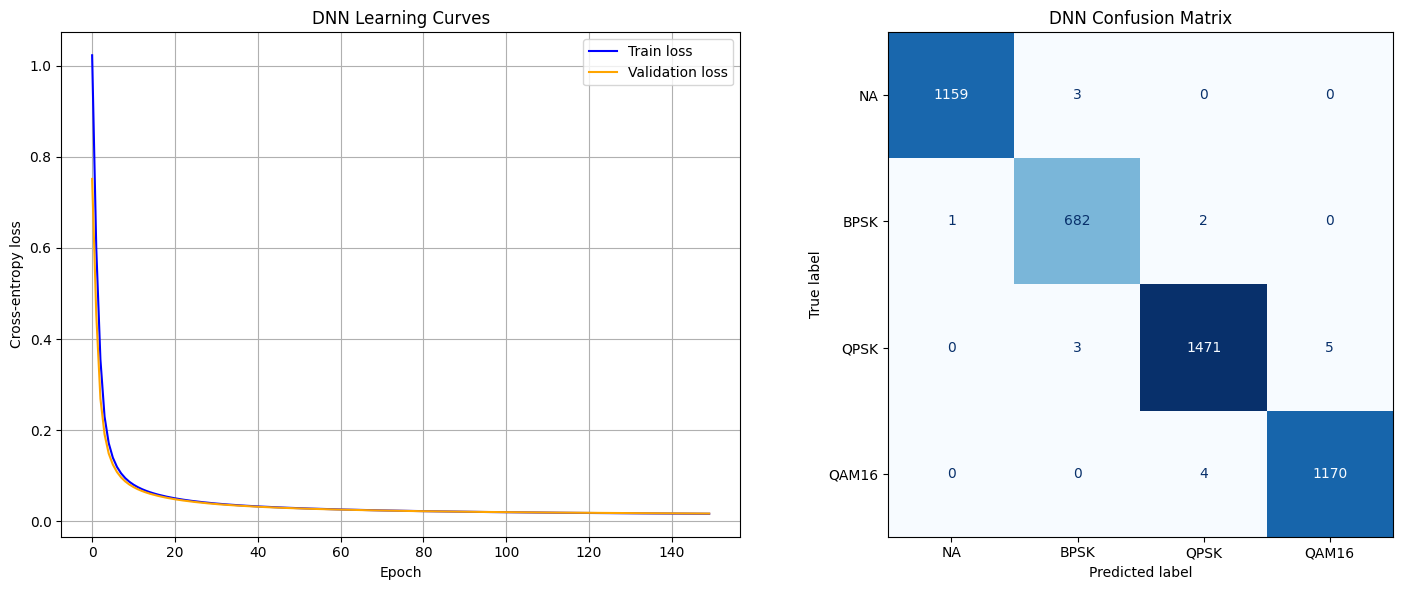

In [13]:
# 7. 예측 및 평가
probs = model.predict(X_test_scaled, verbose=0)
y_pred = probs.argmax(axis=1)

print('\n[시험 데이터 분류 결과]')
print(classification_report(y_test, y_pred, labels=np.arange(4), target_names=labels, zero_division=0))

# 8. 목표 BER 성능 점검
snr_linear = 10 ** (X_test[:, 0]/10)
target_ber = 10 ** X_test[:, 1]
Q = lambda z: 0.5*np.vectorize(erfc)(z/np.sqrt(2))

a_coeff = np.sqrt(snr_linear/5)
ber = np.column_stack([
    np.ones_like(snr_linear),
    Q(np.sqrt(2*snr_linear)),
    Q(np.sqrt(snr_linear)),
    0.75*Q(a_coeff) + 0.5*Q(3*a_coeff) - 0.25*Q(5*a_coeff)
])

violation = (y_pred > 0) & (ber[np.arange(len(y_pred)), y_pred] > target_ber)
missed = (y_pred == 0) & (y_test > 0)

print(f'Target BER 위반율 (전체 시험 샘플 기준): {100*violation.mean():.2f}%')
print(f'전송 기회 누락률 (전체 시험 샘플 기준): {100*missed.mean():.2f}%')

# 9. 모델 저장
model.save('adaptive_modulation_dnn.keras')
print("\n학습된 모델이 'adaptive_modulation_dnn.keras'로 저장되었습니다.")

# 10. 학습 과정 및 혼동행렬 즉시 시각화 출력
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Loss Curve
axs[0].plot(history.history['loss'], label='Train loss', color='blue')
axs[0].plot(history.history['val_loss'], label='Validation loss', color='orange')
axs[0].set_xlabel('Epoch')
axs[0].set_ylabel('Cross-entropy loss')
axs[0].set_title('DNN Learning Curves')
axs[0].grid(True)
axs[0].legend()

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=labels,
    ax=axs[1], cmap='Blues', colorbar=False
)
axs[1].set_title('DNN Confusion Matrix')

plt.tight_layout()
plt.show()